In [1]:
import pandas as pd

from sklearn.metrics import accuracy_score

In [2]:
url = "https://raw.githubusercontent.com/dibyajit-saha/CLustering-of-Murder_crimes-dataset/refs/heads/main/crime_data.csv"
data = pd.read_csv(url)
data.head(3) #first column name is not proper

,Unnamed: 0,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0


In [3]:
data.rename(columns = {'Unnamed: 0' : 'States'},inplace = True)
data.head(3) #changed the first  column name to states

,States,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0


In [4]:
data.isnull().sum() # checked null values

,0
States,0
Murder,0
Assault,0
UrbanPop,0
Rape,0


In [5]:
data.dtypes #checked datatypes

,0
States,object
Murder,float64
Assault,int64
UrbanPop,int64
Rape,float64


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
columns = data.columns
print (columns) # all columns in a list

Index(['States', 'Murder', 'Assault', 'UrbanPop', 'Rape'], dtype='object')


In [8]:
def check_outliers(data, column):
    sns.boxplot(x=data[column])
    plt.show() # function for checking outliers in boxplot

Column Name:  Murder


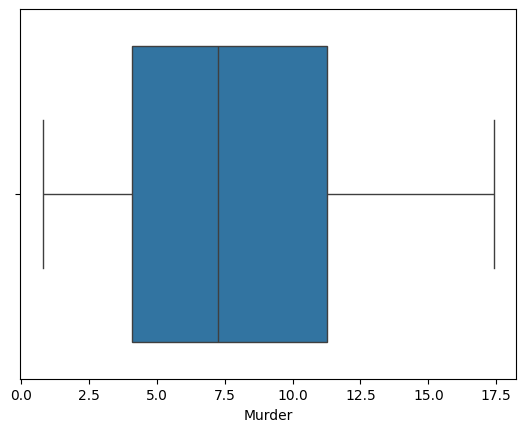

Column Name:  Assault


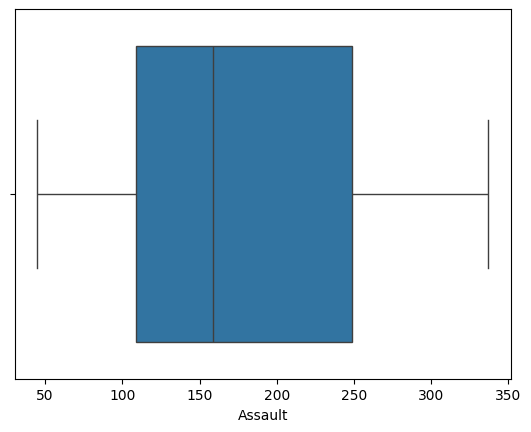

Column Name:  UrbanPop


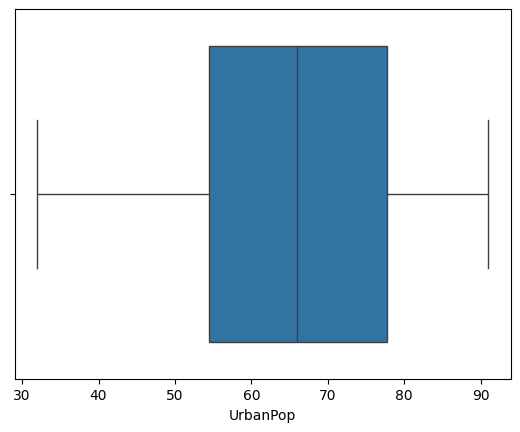

Column Name:  Rape


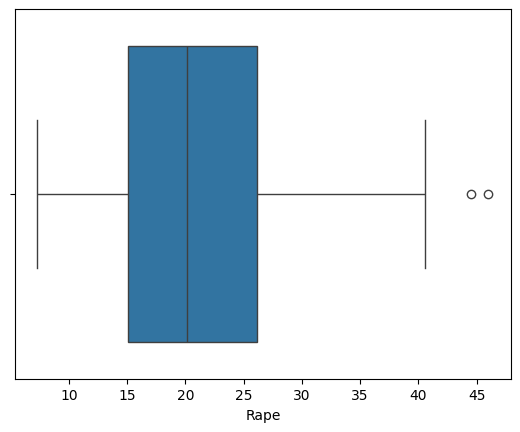

In [9]:
num_cols = data.select_dtypes(include='number')
for i in num_cols:
    print ("Column Name: ", i)
    check_outliers(data,i) # inference = no outliers

In [27]:
data.shape

(50, 5)

In [12]:
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

In [15]:
X = data.columns.drop ('States')
X = data[X]
X_scaled = StandardScaler().fit_transform(X)
X_scaled

array([[ 1.25517927,  0.79078716, -0.52619514, -0.00345116],
       [ 0.51301858,  1.11805959, -1.22406668,  2.50942392],
       [ 0.07236067,  1.49381682,  1.00912225,  1.05346626],
       [ 0.23470832,  0.23321191, -1.08449238, -0.18679398],
       [ 0.28109336,  1.2756352 ,  1.77678094,  2.08881393],
       [ 0.02597562,  0.40290872,  0.86954794,  1.88390137],
       [-1.04088037, -0.73648418,  0.79976079, -1.09272319],
       [-0.43787481,  0.81502956,  0.45082502, -0.58583422],
       [ 1.76541475,  1.99078607,  1.00912225,  1.1505301 ],
       [ 2.22926518,  0.48775713, -0.38662083,  0.49265293],
       [-0.57702994, -1.51224105,  1.21848371, -0.11129987],
       [-1.20322802, -0.61527217, -0.80534376, -0.75839217],
       [ 0.60578867,  0.94836277,  1.21848371,  0.29852525],
       [-0.13637203, -0.70012057, -0.03768506, -0.0250209 ],
       [-1.29599811, -1.39102904, -0.5959823 , -1.07115345],
       [-0.41468229, -0.67587817,  0.03210209, -0.34856705],
       [ 0.44344101, -0.

In [19]:
km = KMeans(n_clusters=5)
km.fit (X_scaled)
pred = km.predict (X_scaled)

In [20]:
data['KMeans'] = pred
data.head(3)

,States,Murder,Assault,UrbanPop,Rape,KMeans
0,Alabama,13.2,236,58,21.2,1
1,Alaska,10.0,263,48,44.5,1
2,Arizona,8.1,294,80,31.0,1


<Axes: xlabel='UrbanPop', ylabel='Murder'>

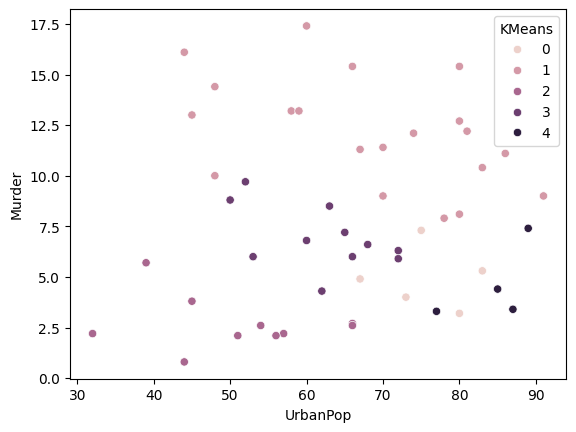

In [53]:
sns.scatterplot(x = 'UrbanPop', y = 'Murder', data = data, hue = 'KMeans' )

<Axes: xlabel='States', ylabel='Assault'>

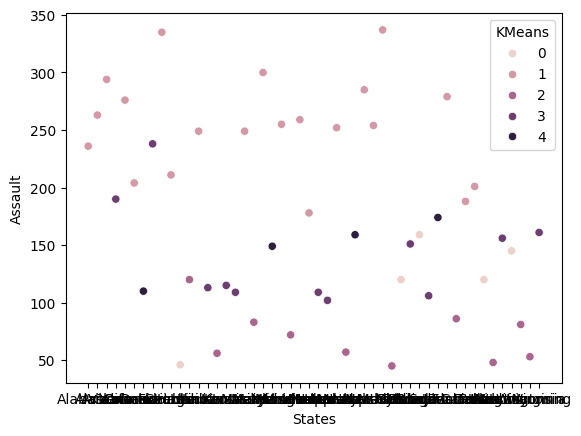

In [23]:
sns.scatterplot(x = 'States', y = 'Assault', data = data, hue = 'KMeans' )

<Axes: xlabel='UrbanPop', ylabel='UrbanPop'>

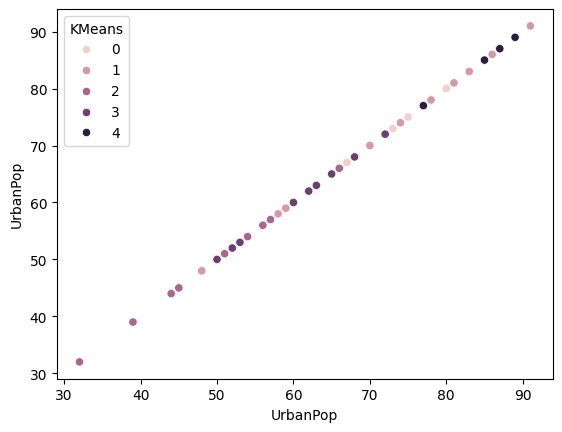

In [54]:
sns.scatterplot(x = 'UrbanPop', y = 'UrbanPop', data = data, hue = 'KMeans' )

<Axes: xlabel='UrbanPop', ylabel='Rape'>

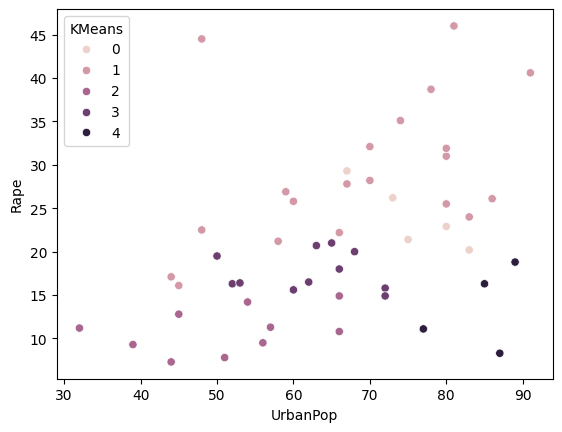

In [55]:
sns.scatterplot(x = 'UrbanPop', y = 'Rape', data = data, hue = 'KMeans' )

In [26]:
from math import sqrt
sqrt(len(data)/2)

5.0

In [72]:
wcss = []
k = range(1,11)
for i in k:
  km = KMeans(n_clusters=i)
  km.fit(X_scaled)
  wcss.append(km.inertia_)
print(wcss)

[200.0, 104.96163315756873, 93.21138200589303, 58.237193843606825, 53.06687829356683, 45.59204161261911, 40.587873651745035, 40.26179347734201, 32.89262624855674, 29.129101804582024]


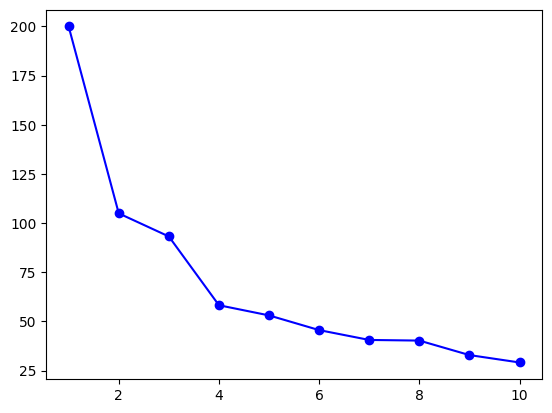

In [73]:
plt.plot(k,wcss,'bo-' )

In [74]:
score = silhouette_score(X_scaled,pred) ### More towards 1 the more better it is
print(score)

0.2432705451574941


In [81]:
km = KMeans(n_clusters=3)
km.fit (X_scaled)
pred3 = km.predict (X_scaled)
score = silhouette_score(X_scaled,pred3) ### More towards 1 the more better it is
print(score)

0.36682842761846884


In [82]:
km = KMeans(n_clusters=4)
km.fit (X_scaled)
pred3 = km.predict (X_scaled)
score = silhouette_score(X_scaled,pred3) ### More towards 1 the more better it is
print(score)

0.33968891433344395


In [83]:
scores = []

for k in range(2, 11):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    scores.append(score)

    print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=0.4085
K=3, Silhouette Score=0.3081
K=4, Silhouette Score=0.3397
K=5, Silhouette Score=0.3008
K=6, Silhouette Score=0.2939
K=7, Silhouette Score=0.2742
K=8, Silhouette Score=0.2357
K=9, Silhouette Score=0.2581
K=10, Silhouette Score=0.2543


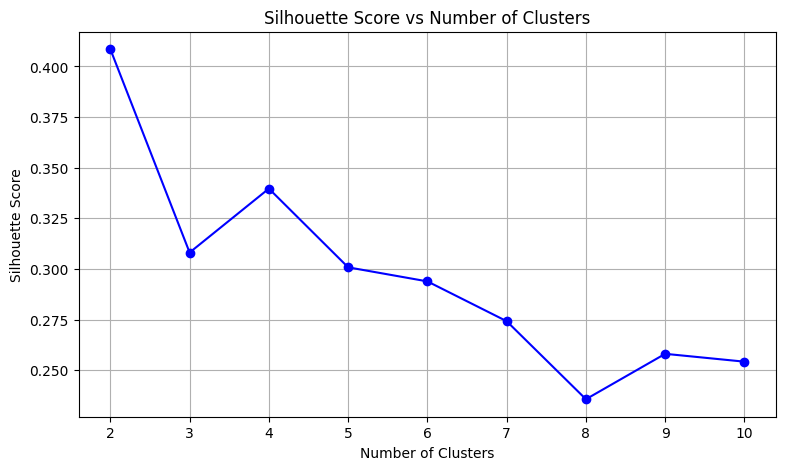

In [84]:
plt.figure(figsize=(9,5))

plt.plot(range(2,11), scores, 'bo-')

plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')

plt.xticks(range(2,11))
plt.grid(True)

plt.show()

In [77]:
data['KM3'] = pred3

Column name:  Murder


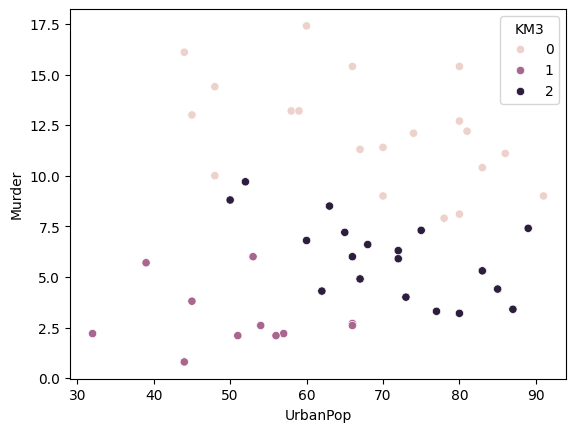

Column name:  Assault


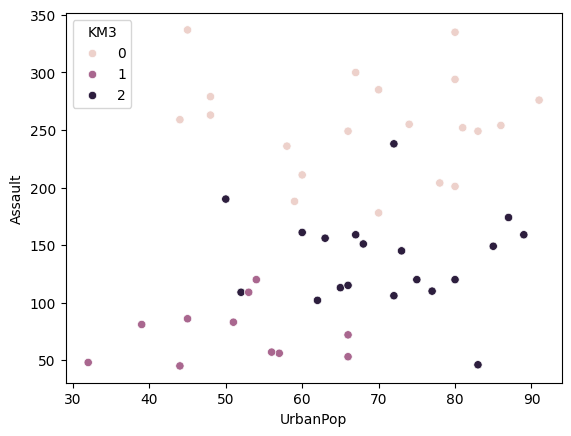

Column name:  UrbanPop


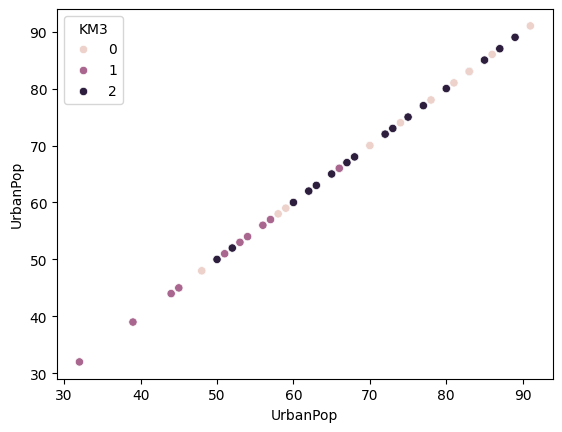

Column name:  Rape


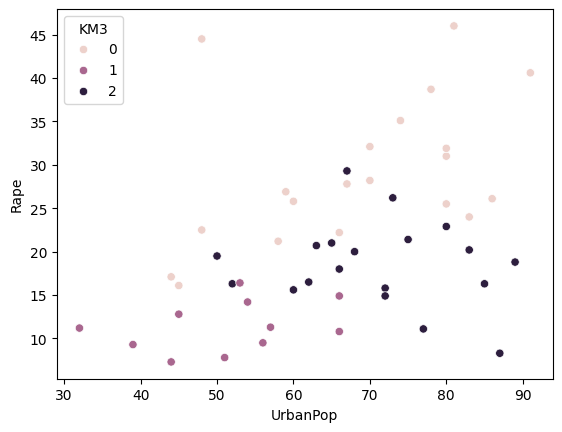

In [78]:
for i in X:
  print ('Column name: ',i)
  sns.scatterplot(x = 'UrbanPop', y = i, data = data, hue = 'KM3' )
  plt.show()

In [86]:
cluster_profile = data.groupby('KM3')[
    ['Murder', 'Assault', 'UrbanPop', 'Rape']
].mean()

print(cluster_profile.round(2))

     Murder  Assault  UrbanPop   Rape
KM3                                  
0     12.16   255.25     68.40  29.16
1      2.98    73.64     51.18  11.41
2      5.96   138.05     70.84  18.57


In [89]:
cluster_profile = data.groupby('KM3')[
    ['Murder', 'Assault', 'UrbanPop', 'Rape']
].count()

print(cluster_profile.round(2))

     Murder  Assault  UrbanPop  Rape
KM3                                 
0        20       20        20    20
1        11       11        11    11
2        19       19        19    19


In [66]:
## Agglo
for linkage_method in ['ward', 'complete', 'average']:

    agg = AgglomerativeClustering(
        n_clusters=3,
        linkage=linkage_method
    )

    labels = agg.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(linkage_method, score)

ward 0.31036358174027895
complete 0.36924314190439733
average 0.34863679190476177


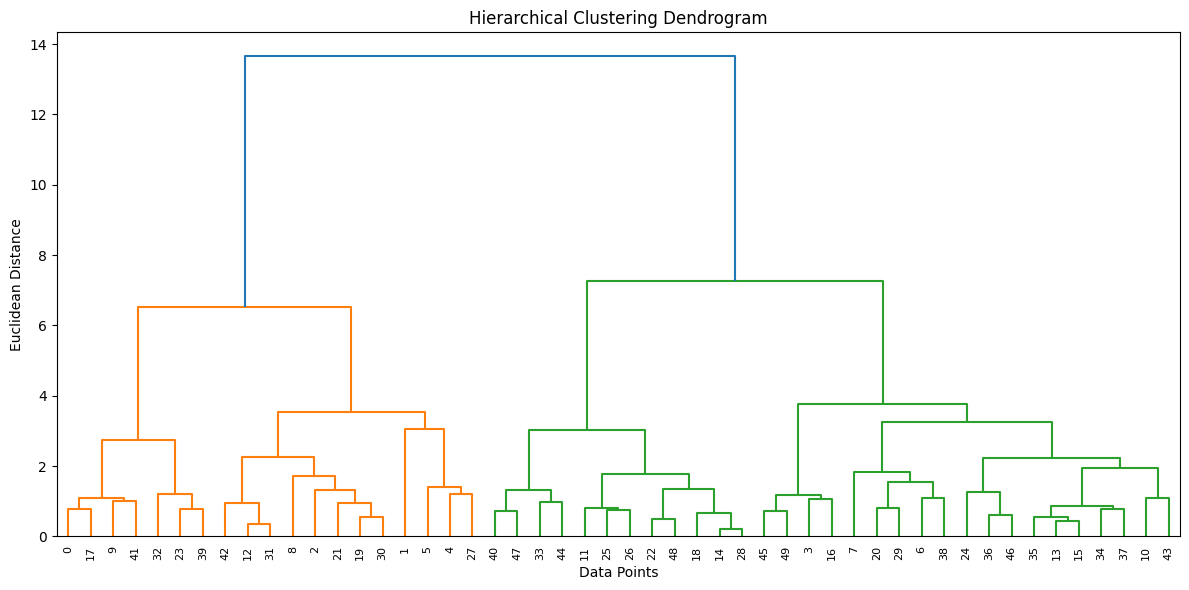

In [79]:
# Perform hierarchical clustering
Z = linkage(X_scaled, method='ward', metric='euclidean')

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distance')
plt.tight_layout()
plt.show()

In [80]:
data['agglo'] = pred_agg
data

,States,Murder,Assault,UrbanPop,Rape,KMeans,KM3,agglo
0,Alabama,13.2,236,58,21.2,1,0,0
1,Alaska,10.0,263,48,44.5,1,0,1
2,Arizona,8.1,294,80,31.0,1,0,0
3,Arkansas,8.8,190,50,19.5,3,2,0
4,California,9.0,276,91,40.6,1,0,0
5,Colorado,7.9,204,78,38.7,1,0,0
6,Connecticut,3.3,110,77,11.1,4,2,0
7,Delaware,5.9,238,72,15.8,3,2,0
8,Florida,15.4,335,80,31.9,1,0,2
9,Georgia,17.4,211,60,25.8,1,0,0


In [70]:
cluster_profile = data.groupby('agglo')[
    ['Murder', 'Assault', 'UrbanPop', 'Rape']
].mean()

print(cluster_profile.round(2))

       Murder  Assault  UrbanPop   Rape
agglo                                  
0        7.58   165.42      65.6  20.52
1       10.00   263.00      48.0  44.50
2       15.40   335.00      80.0  31.90


In [ ]:
cluster_profile = data.groupby('agglo')[
    ['Murder', 'Assault', 'UrbanPop', 'Rape']
].mean()

print(cluster_profile.round(2))

In [71]:
analysis_data = data.drop(
    columns=['KMeans', 'KM3', 'agglo'],
    errors='ignore'
).copy()

analysis_data['Cluster'] = results['Cluster']

cluster_profile = analysis_data.groupby('Cluster')[
    ['Murder', 'Assault', 'UrbanPop', 'Rape']
].mean()

print(cluster_profile.round(2))

NameError: name 'results' is not defined